# Attention and KV Cache

**Implemented and environment prepared; project tests passed, experiment execution pending.**

On 28 September 2026, the owner stopped the first training attempt and removed its runs. This fresh version reduces GPU synchronization, reuses one causal mask across layers and forwards, and uses **microbatch 4 × accumulation 2**, still **8,192 predicted tokens per full optimizer update**. FP32, the architecture, data and three-epoch budget are unchanged. See the [optimization checks](../reviews/optimization-2026-09-28/README.md).

**Restart the kernel before using this revision.** Keep `RUN_MODE="new"` and `RESUME_RUN_ID=None`; a new run verifies and reuses matching project-level data/tokenizer caches. Run the preparation and correctness cells in order before training. The prior executed notebook is preserved in the optimization review folder. The [27 September test/download record](../reviews/validation-2026-09-27/README.md) is historical; its old run ID is no longer a resume target.

Compare MHA, GQA, and MQA on the same TinyStories subset and training budget. Select **Attention KV Cache — Python 3.13**. Every code cell has one responsibility; implementation lives in `src`.

**Run All executes data preparation, correctness checks, three training fits, evaluation, and benchmarks.** This revised notebook is output-free; the full optimized experiment has not been started. Step through it deliberately for the first run.

A fresh run gets a new numbered folder. To recover an interrupted run, use explicit resume mode in the configuration cell. Completed fits are reused after identity verification.

Research: [Transformer](https://arxiv.org/abs/1706.03762), [MQA](https://arxiv.org/abs/1911.02150), [GQA](https://aclanthology.org/2023.emnlp-main.298/), [TinyStories](https://arxiv.org/abs/2305.07759). This is an inspired small-model experiment, not a reproduction of those papers.

### Locate this project

Open from the project, its notebooks directory, or the Growth workspace. No project package installation is needed.

In [1]:
from pathlib import Path
import sys

candidates = (Path.cwd(), Path.cwd().parent, Path.cwd() / "labs" / "attention-kv-cache")
PROJECT_ROOT = next((p.resolve() for p in candidates if p.name == "attention-kv-cache" and (p / "src" / "config.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from attention-kv-cache, its notebooks directory, or the Growth workspace")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
PROJECT_ROOT

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache')

### Import notebook interfaces

Imports define interfaces; they do not download data or start experiments.

In [2]:
import pandas as pd
import src
from src.config import DataConfig, ModelConfig, TrainConfig, BenchmarkConfig, ExperimentConfig
from src.runs import start_run, close_run
from src.runtime import inspect_environment, select_device, release_memory
from src.data import download_source, prepare_splits, inspect_split_audit, prepare_tokens, inspect_window
from src.tokenizer import train_tokenizer, inspect_tokenization
from src.diagnostics import inspect_model, run_correctness_checks, plot_attention, inspect_cache_growth, compare_cached_outputs
from src.train import train_variant
from src.evaluate import fit_unigram, evaluate_unigram, evaluate_variant
from src.checkpoints import freeze_primary_checkpoints, load_model
from src.benchmark import prepare_benchmark_fixtures, benchmark_variant
from src.generate import generate_variant
from src.tracking import training_summary
from src.reporting import (plot_story_lengths, plot_training_curves, plot_learning_rate, comparison_table,
                           plot_cache_growth, plot_prefill_latency, plot_decode_latency, quality_cost_table, assemble_report)
assert Path(src.__file__).resolve().parent == PROJECT_ROOT / "src", "Restart the kernel: src points to another project"

### Choose the immutable experiment configuration

All three variants use this recipe. Change settings before creating a fresh run. Resume requires exactly the recorded source, configuration, environment, and data. One seed gives three fits; it does not establish a seed-robust ranking.

Four sequences per microbatch and two accumulation steps preserve eight sequences per full optimizer update. The final partial group still uses its actual token count. Train loss is now the token-weighted mean over each logging interval; throughput includes batch preparation and synchronized model updates, excluding checkpoint and log writes. Progress loss refreshes at that interval.

In [3]:
RUN_MODE = "new"       # "new" or "resume"
RESUME_RUN_ID = None    # For resume, e.g. "run_001"
SHOW_TENSORBOARD = True

CONFIG = ExperimentConfig(
    data=DataConfig(dataset="roneneldan/TinyStories", revision="main", train_stories=250_000,
                    split_seed=2027, vocab_size=8192, context_length=1024),
    model=ModelConfig(vocab_size=8192, num_layers=6, d_model=384, num_query_heads=8,
                      num_kv_heads=8, ffn_dim=1024, norm_eps=1e-5, rope_base=10_000.0,
                      max_seq_len=4096, seed=2027),
    train=TrainConfig(seed=2027, epochs=3, microbatch_size=4, accumulation_steps=2,
                      learning_rate=3e-4, min_learning_rate=3e-5, betas=(0.9, 0.95),
                      weight_decay=0.1, warmup_fraction=0.05, gradient_clip=1.0,
                      checkpoint_interval=250, log_interval=10),
    benchmark=BenchmarkConfig(prompt_lengths=(128, 256, 512, 1024, 2048), batch_sizes=(1, 4),
                              decode_steps=128, warmup_trials=5, measured_trials=20),
    atol=1e-5, rtol=1e-4,
)
CONFIG.to_dict()

{'data': {'dataset': 'roneneldan/TinyStories',
  'revision': 'main',
  'train_stories': 250000,
  'split_seed': 2027,
  'vocab_size': 8192,
  'context_length': 1024},
 'model': {'vocab_size': 8192,
  'num_layers': 6,
  'd_model': 384,
  'num_query_heads': 8,
  'num_kv_heads': 8,
  'ffn_dim': 1024,
  'norm_eps': 1e-05,
  'rope_base': 10000.0,
  'max_seq_len': 4096,
  'seed': 2027},
 'train': {'seed': 2027,
  'epochs': 3,
  'microbatch_size': 4,
  'accumulation_steps': 2,
  'learning_rate': 0.0003,
  'min_learning_rate': 3e-05,
  'betas': (0.9, 0.95),
  'weight_decay': 0.1,
  'warmup_fraction': 0.05,
  'gradient_clip': 1.0,
  'checkpoint_interval': 250,
  'log_interval': 10},
 'benchmark': {'prompt_lengths': (128, 256, 512, 1024, 2048),
  'batch_sizes': (1, 4),
  'decode_steps': 128,
  'warmup_trials': 5,
  'measured_trials': 20},
 'atol': 1e-05,
 'rtol': 0.0001}

### Start or resume one run

Rerunning this cell in fresh mode creates the next run number. Other cells use the selected run; they do not allocate new runs.

In [4]:
run = start_run(PROJECT_ROOT, CONFIG, mode=RUN_MODE, run_id=RESUME_RUN_ID)
run.path

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001')

### Inspect the selected environment

Device order is MPS → CUDA → CPU. Unsupported operations or allocation failures stop explicitly. Memory readings are snapshots, not exact peaks.

In [5]:
environment = inspect_environment(run)
environment

{'device': 'mps',
 'torch': '2.14.0',
 'precision': 'float32',
 'fallback': False,
 'memory': {'process_rss_bytes': 331743232,
  'system_available_bytes': 6722748416,
  'system_swap_used_bytes': 973012992,
  'measurement': 'instantaneous snapshot, not an exact peak; unified-memory categories overlap',
  'mps_tensor_bytes': 0,
  'mps_driver_bytes': 393216},
 'bitwise_reproducibility_claim': False}

### Optional TensorBoard viewer

Set SHOW_TENSORBOARD=True to start a local viewer. The event files remain under this run. This viewer is tooling, not a project CLI, and never starts training.

In [6]:
if SHOW_TENSORBOARD:
    import shlex
    from tensorboard import notebook as tensorboard_notebook
    tensorboard_notebook.start(f"--logdir {shlex.quote(str(run.path / 'tensorboard'))} --host 127.0.0.1")

### Download and pin the source

First execution resolves main to an immutable revision and downloads the original train/validation corpus into this project. Reruns verify the recorded cache.

In [7]:
source_receipt = download_source(run)
source_receipt

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/data_manifest/source_receipt.json')

### Prepare the subset and held-out splits

Exact normalized duplicates are removed. The official validation split supplies our derived validation/test halves; training overlaps are excluded before selecting 250,000 stories. Near duplicates remain a limitation.

In [8]:
splits = prepare_splits(run, source_receipt)
splits

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/data/splits/a139db1d553f91c35b3b91343a74567b2e0887b08e03aa0b1cf31c82611a2e12')

### Inspect split provenance

Audit counts, exclusions, hashes, and the origin of the derived test set.

In [9]:
split_audit = inspect_split_audit(splits)
split_audit

{'counts': {'duplicate_train': 320241,
  'duplicate_validation': 0,
  'eligible_unique_train': 1792647,
  'empty_train': 230,
  'empty_validation': 0,
  'selected_train': 250000,
  'source_train': 2119719,
  'source_validation': 21990,
  'test': 10995,
  'train_heldout_overlap': 6601,
  'unselected_unique_train': 1542647,
  'validation': 10995},
 'exclusions': {'entries': 1869719, 'file': 'exclusions.jsonl'},
 'files': {'exclusions.jsonl': '9c5e6f43ec3cf749cee086b0679f48f6c0ad7658705b718e29f743dc3ae2c146',
  'test.jsonl': '5bd0b2bc5c336a8a00f7d5506257d192ef015cbbd5847db0e8cc2bbf4a1496a0',
  'train.jsonl': '7c5c9a624c4f4dd47ab3fec12a9b3a93daf19bdf8221c134d0595d926f1ec785',
  'validation.jsonl': 'dde77833d6739e334608ae89bfd4891fcb110263e558a425a19658210066a55d'},
 'heldout_partition': 'sort unique hashes; first floor(N/2) validation, remainder test',
 'identity': {'protocol': 'tinystories-nfc-exact-dedup-v1',
  'seed': 2027,
  'source_manifest_sha256': 'b8dc02b6a6ece2194bf82940614f63adb1

### Plot training-story lengths

This descriptive figure uses selected training stories only.

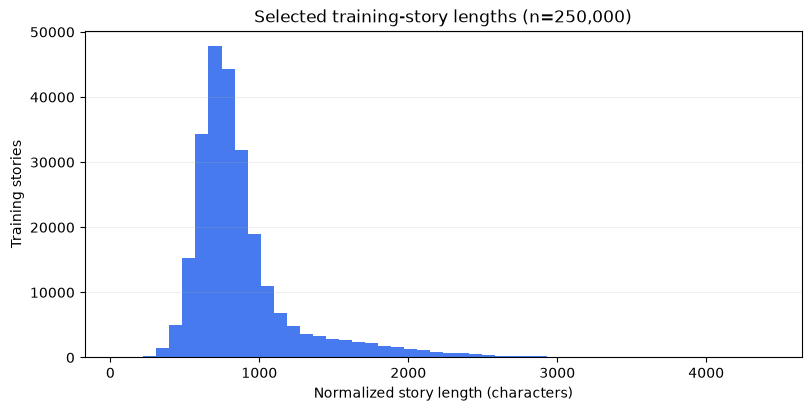

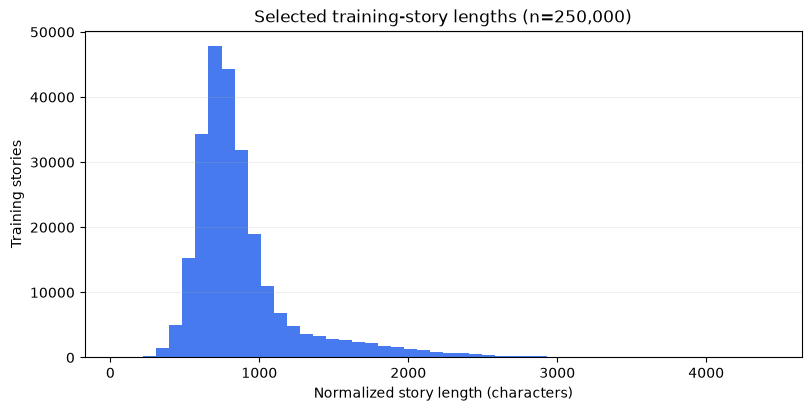

In [10]:
plot_story_lengths(run, splits)

### Train or load the shared tokenizer

Byte-level BPE learns only from selected training stories. The tokenizer and special IDs are frozen for all three models.

In [11]:
tokenizer_path = train_tokenizer(run, splits)
tokenizer_path

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/tokenizer/tokenizer.json')

### Inspect a tokenization example

Tokens are byte-level subwords. This view does not fit anything.

In [12]:
inspect_tokenization(tokenizer_path, "Lily found a small blue box under the old tree.")

{'text': 'Lily found a small blue box under the old tree.',
 'ids': [346, 593, 261, 793, 1083, 788, 893, 265, 691, 678, 16],
 'tokens': ['Lily',
  'Ġfound',
  'Ġa',
  'Ġsmall',
  'Ġblue',
  'Ġbox',
  'Ġunder',
  'Ġthe',
  'Ġold',
  'Ġtree',
  '.'],
 'decoded': 'Lily found a small blue box under the old tree.',
 'token_count': 11,
 'special_tokens_added': False}

### Prepare disk-backed token windows

Every story has BOS/EOS markers. Causal context may cross stories; EOS is not an attention reset. Train tails are counted and dropped; held-out tails are padded with ignored targets.

In [13]:
tokens = prepare_tokens(run, splits, tokenizer_path)
tokens.manifest

{'bos_id': 1,
 'boundary_policy': 'Concatenate BOS,text,EOS stories. Attention crosses story boundaries; no cache reset.',
 'context_length': 1024,
 'dtype': '<u4',
 'eos_id': 2,
 'files': {'test.bin': 'eb71d6e9fcfe4d1584b21c5a2ba8e5992890508bef376ae0a27d1105cf915297',
  'train.bin': 'e3961fd98712b78c1f3ab846bdc269fd09a99800f8d48ae69b71d0c948174007',
  'validation.bin': 'ca741a753137e934927aada233da9c8d08128e86ecf65c523ebb7e5ff457ac03'},
 'identity': {'context_length': 1024,
  'protocol': 'byte-bpe-bos-eos-contiguous-u32le-v1',
  'splits_manifest_sha256': 'be3f09f1174a3d9833b4a982e136c11b4e1f47edafc2783fd8975d6a9cbda12c',
  'tokenizer_sha256': '1c704470c384d45ef7de1649eb1c5b9af464693bc5b8a0cc229db9c03969af2e'},
 'pad_id': 0,
 'splits': {'test': {'discarded_tail_tokens': 0,
   'discarded_target_tokens': 0,
   'file': 'test.bin',
   'predicted_tokens': 2358938,
   'sha256': 'eb71d6e9fcfe4d1584b21c5a2ba8e5992890508bef376ae0a27d1105cf915297',
   'stories': 10995,
   'token_count': 2358939,

### Inspect one next-token window

Inputs and targets are shifted by exactly one token. The context is 1,024 predicted positions.

In [14]:
inspect_window(tokens, index=0)

{'window_index': 0,
 'input_ids': [1,
  6951,
  362,
  261,
  5886,
  684,
  16,
  315,
  446,
  268,
  3380,
  306,
  481,
  518,
  265,
  763,
  16,
  955,
  340,
  1787,
  265,
  5886,
  684,
  14,
  306,
  929,
  893,
  265,
  2366,
  16,
  5623,
  614,
  634,
  347,
  1066,
  267,
  6324,
  267,
  517,
  893,
  265,
  2366,
  14,
  410,
  265,
  5886,
  684,
  362,
  2793,
  3,
  5623,
  284,
  2602,
  14,
  353,
  340,
  622,
  268,
  654,
  368,
  568,
  1474,
  268,
  361,
  344,
  16,
  409,
  201,
  1065,
  14,
  5623,
  2225,
  261,
  1610,
  16,
  412,
  284,
  261,
  3743,
  1610,
  359,
  3809,
  530,
  2325,
  746,
  340,
  2083,
  306,
  16,
  5623,
  1405,
  1007,
  360,
  265,
  1610,
  267,
  1129,
  1507,
  71,
  92,
  266,
  306,
  16,
  412,
  284,
  1270,
  14,
  515,
  311,
  5886,
  684,
  3,
  315,
  622,
  268,
  867,
  360,
  267,
  634,
  267,
  550,
  265,
  1610,
  3380,
  360,
  267,
  634,
  16,
  5623,
  501,
  418,
  340,
  3752,
  265,
  1610,
  1018

### Inspect MHA architecture

Save the reconstructable architecture, readable module tree, parameter counts, and theoretical cache bytes. This cell does not train.

In [15]:
mha_architecture = inspect_model(run, "mha")
mha_architecture

{'variant': 'mha',
 'config': {'vocab_size': 8192,
  'num_layers': 6,
  'd_model': 384,
  'num_query_heads': 8,
  'num_kv_heads': 8,
  'ffn_dim': 1024,
  'norm_eps': 1e-05,
  'rope_base': 10000.0,
  'max_seq_len': 4096,
  'seed': 2027},
 'attention_backend': 'compact_grouped_bmm',
 'parameter_count': 13767552,
 'trainable_parameter_count': 13767552,
 'weight_bytes_fp32': 55070208,
 'kv_bytes_per_token_per_sequence_fp32': 18432,
 'tied_embedding_and_output': True,
 'initialization': 'SHA256(seed:parameter_name); normal std=0.02; residual projections scaled by sqrt(2*layers); RMSNorm=1',
 'dropout': 0.0,
 'parameter_shapes': {'embedding.weight': [8192, 384],
  'layers.0.attention_norm.weight': [384],
  'layers.0.attention.q_proj.weight': [384, 384],
  'layers.0.attention.k_proj.weight': [384, 384],
  'layers.0.attention.v_proj.weight': [384, 384],
  'layers.0.attention.o_proj.weight': [384, 384],
  'layers.0.ffn_norm.weight': [384],
  'layers.0.mlp.gate_proj.weight': [1024, 384],
  'laye

### Inspect GQA architecture

Save the reconstructable architecture, readable module tree, parameter counts, and theoretical cache bytes. This cell does not train.

In [16]:
gqa_architecture = inspect_model(run, "gqa")
gqa_architecture

{'variant': 'gqa',
 'config': {'vocab_size': 8192,
  'num_layers': 6,
  'd_model': 384,
  'num_query_heads': 8,
  'num_kv_heads': 2,
  'ffn_dim': 1024,
  'norm_eps': 1e-05,
  'rope_base': 10000.0,
  'max_seq_len': 4096,
  'seed': 2027},
 'attention_backend': 'compact_grouped_bmm',
 'parameter_count': 12440448,
 'trainable_parameter_count': 12440448,
 'weight_bytes_fp32': 49761792,
 'kv_bytes_per_token_per_sequence_fp32': 4608,
 'tied_embedding_and_output': True,
 'initialization': 'SHA256(seed:parameter_name); normal std=0.02; residual projections scaled by sqrt(2*layers); RMSNorm=1',
 'dropout': 0.0,
 'parameter_shapes': {'embedding.weight': [8192, 384],
  'layers.0.attention_norm.weight': [384],
  'layers.0.attention.q_proj.weight': [384, 384],
  'layers.0.attention.k_proj.weight': [96, 384],
  'layers.0.attention.v_proj.weight': [96, 384],
  'layers.0.attention.o_proj.weight': [384, 384],
  'layers.0.ffn_norm.weight': [384],
  'layers.0.mlp.gate_proj.weight': [1024, 384],
  'layers.

### Inspect MQA architecture

Save the reconstructable architecture, readable module tree, parameter counts, and theoretical cache bytes. This cell does not train.

In [17]:
mqa_architecture = inspect_model(run, "mqa")
mqa_architecture

{'variant': 'mqa',
 'config': {'vocab_size': 8192,
  'num_layers': 6,
  'd_model': 384,
  'num_query_heads': 8,
  'num_kv_heads': 1,
  'ffn_dim': 1024,
  'norm_eps': 1e-05,
  'rope_base': 10000.0,
  'max_seq_len': 4096,
  'seed': 2027},
 'attention_backend': 'compact_grouped_bmm',
 'parameter_count': 12219264,
 'trainable_parameter_count': 12219264,
 'weight_bytes_fp32': 48877056,
 'kv_bytes_per_token_per_sequence_fp32': 2304,
 'tied_embedding_and_output': True,
 'initialization': 'SHA256(seed:parameter_name); normal std=0.02; residual projections scaled by sqrt(2*layers); RMSNorm=1',
 'dropout': 0.0,
 'parameter_shapes': {'embedding.weight': [8192, 384],
  'layers.0.attention_norm.weight': [384],
  'layers.0.attention.q_proj.weight': [384, 384],
  'layers.0.attention.k_proj.weight': [48, 384],
  'layers.0.attention.v_proj.weight': [48, 384],
  'layers.0.attention.o_proj.weight': [384, 384],
  'layers.0.ffn_norm.weight': [384],
  'layers.0.mlp.gate_proj.weight': [1024, 384],
  'layers.

### Check attention and cache correctness

Small CPU reference/gradient checks plus selected-device cache checks must pass before training. Strict tolerances are recorded; failures stop the experiment.

In [18]:
correctness = run_correctness_checks(run)
correctness

{'passed': True,
 'atol': 1e-05,
 'rtol': 0.0001,
 'device': 'mps',
 'run_identity': {'config': 'd2c73123277c40765407c0639eadee4c8119fbb183e677ed13fbb21f853e2df5',
  'environment': '848c8ee1ebedf04e29385547596bc1194b926e2e134b759979f38d35e73e32a9',
  'source': '136a46465a97fb525a50e318a9fc3cd055328b920e995805961ede7d6f4f6a2c'},
 'model_config': {'vocab_size': 8192,
  'num_layers': 6,
  'd_model': 384,
  'num_query_heads': 8,
  'num_kv_heads': 8,
  'ffn_dim': 1024,
  'norm_eps': 1e-05,
  'rope_base': 10000.0,
  'max_seq_len': 4096,
  'seed': 2027},
 'tests': [{'name': 'grouped_bmm_output_and_gradients',
   'device': 'cpu',
   'kv_heads': 8,
   'offset': 0,
   'query_length': 5,
   'passed': True,
   'max_absolute_error': 3.5762786865234375e-07},
  {'name': 'grouped_bmm_output_and_gradients',
   'device': 'cpu',
   'kv_heads': 8,
   'offset': 3,
   'query_length': 2,
   'passed': True,
   'max_absolute_error': 2.384185791015625e-07},
  {'name': 'grouped_bmm_output_and_gradients',
   'dev

### Fit the simple baseline

Fit an add-one-smoothed unigram distribution using training targets only.

In [19]:
unigram = fit_unigram(run, tokens)
unigram

Fit unigram:   0%|          | 0/419 [00:00<?, ?it/s]

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/unigram.npz')

### Evaluate the baseline on validation

Validation provides the initial reference. Test evaluation remains after final checkpoints are frozen.

In [20]:
evaluate_unigram(run, tokens, unigram, split="validation")

Unigram validation:   0%|          | 0/18 [00:00<?, ?it/s]

{'total_nll': 14026864.582820252,
 'predicted_tokens': 2354442,
 'nll': 5.957617381451848,
 'perplexity': 386.6876964994175,
 'perplexity_overflow': False,
 'variant': 'unigram',
 'split': 'validation',
 'windows': 2300,
 'split_origin': 'derived from the official validation split',
 'baseline_sha256': 'a1761dcbc0c7e40eeb539cde5aaf40f6ef11e5039c8790571df0aeb5372ed7c5',
 'token_manifest_sha256': '993ead9059c284a7347258aa6cafc9fa195fe09c7b2761752e4fcb4cea888dc4',
 'path': '/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/unigram_validation.json'}

### Train MHA

One selected architecture, three fixed epochs. This cell creates latest/best/final checkpoints. Interruptions resume only after selecting resume mode; completed fits return verified saved results.

In [21]:
mha_fit = train_variant(run, tokens, "mha")
mha_fit

MHA epoch 1/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

MHA epoch 2/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

MHA epoch 3/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

{'variant': 'mha',
 'status': 'complete',
 'epochs': 3,
 'tokens_seen': 164637696,
 'optimizer_updates': 20100,
 'final_checkpoint': 'models/mha/final.pt',
 'final_sha256': '73b17ae13844a61d62f6418a7d75ac7fb772882a7e76c7d25b4b8691fcdaddd6',
 'best_validation_nll': 1.6104699159145246,
 'validation_at_final': {'total_nll': 3791758.009765625,
  'predicted_tokens': 2354442,
  'nll': 1.6104699159145246,
  'perplexity': 5.005162680896246,
  'perplexity_overflow': False,
  'windows': 2300,
  'padding_targets': 758,
  'elapsed_seconds': 57.8185676250032},
 'device': 'mps',
 'single_seed': 2027}

### Train GQA

One selected architecture, three fixed epochs. This cell creates latest/best/final checkpoints. Interruptions resume only after selecting resume mode; completed fits return verified saved results.

In [22]:
gqa_fit = train_variant(run, tokens, "gqa")
gqa_fit

GQA epoch 1/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

GQA epoch 2/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

GQA epoch 3/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

{'variant': 'gqa',
 'status': 'complete',
 'epochs': 3,
 'tokens_seen': 164637696,
 'optimizer_updates': 20100,
 'final_checkpoint': 'models/gqa/final.pt',
 'final_sha256': '1266c5fe770d878ce6955fc878521b2d9b27e647017112e68c667bf2b8cc4493',
 'best_validation_nll': 1.6104323479217024,
 'validation_at_final': {'total_nll': 3791669.5581054688,
  'predicted_tokens': 2354442,
  'nll': 1.6104323479217024,
  'perplexity': 5.004974650512561,
  'perplexity_overflow': False,
  'windows': 2300,
  'padding_targets': 758,
  'elapsed_seconds': 53.685301792000246},
 'device': 'mps',
 'single_seed': 2027}

### Train MQA

One selected architecture, three fixed epochs. This cell creates latest/best/final checkpoints. Interruptions resume only after selecting resume mode; completed fits return verified saved results.

In [23]:
mqa_fit = train_variant(run, tokens, "mqa")
mqa_fit

MQA epoch 1/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

MQA epoch 2/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

MQA epoch 3/3:   0%|          | 0/6700 [00:00<?, ?update/s]

Evaluate:   0%|          | 0/575 [00:00<?, ?it/s]

{'variant': 'mqa',
 'status': 'complete',
 'epochs': 3,
 'tokens_seen': 164637696,
 'optimizer_updates': 20100,
 'final_checkpoint': 'models/mqa/final.pt',
 'final_sha256': '9cdc2028264f67a7fef1414616ea47dbb016119cbfa4520a0e3c9996b174dce6',
 'best_validation_nll': 1.6169444164278097,
 'validation_at_final': {'total_nll': 3807001.845703125,
  'predicted_tokens': 2354442,
  'nll': 1.6169444164278097,
  'perplexity': 5.037673742114447,
  'perplexity_overflow': False,
  'windows': 2300,
  'padding_targets': 758,
  'elapsed_seconds': 53.061908499999845},
 'device': 'mps',
 'single_seed': 2027}

### Inspect fit completion

Check equal token budgets, update counts, and final checkpoint identities.

In [24]:
pd.DataFrame(training_summary(run))

,best_validation_nll,device,epochs,final_checkpoint,final_sha256,optimizer_updates,single_seed,status,tokens_seen,validation_at_final,variant
0,1.610470,mps,3,models/mha/final.pt,73b17ae13844a61d62f6418a7d75ac7fb772882a7e76c7...,20100,2027,complete,164637696,"{'elapsed_seconds': 57.8185676250032, 'nll': 1...",mha
1,1.610432,mps,3,models/gqa/final.pt,1266c5fe770d878ce6955fc878521b2d9b27e647017112...,20100,2027,complete,164637696,"{'elapsed_seconds': 53.685301792000246, 'nll':...",gqa
2,1.616944,mps,3,models/mqa/final.pt,9cdc2028264f67a7fef1414616ea47dbb016119cbfa452...,20100,2027,complete,164637696,"{'elapsed_seconds': 53.061908499999845, 'nll':...",mqa


### Plot learning curves

Training and complete-validation curves are retained. A lower training loss alone is not evidence of better held-out behavior.

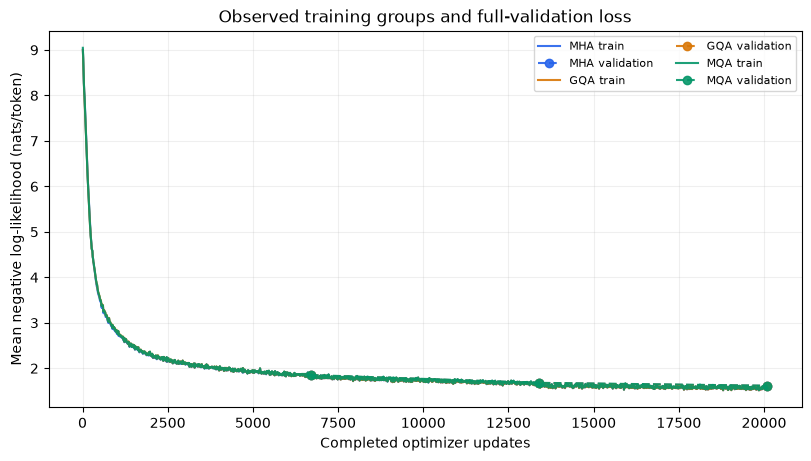

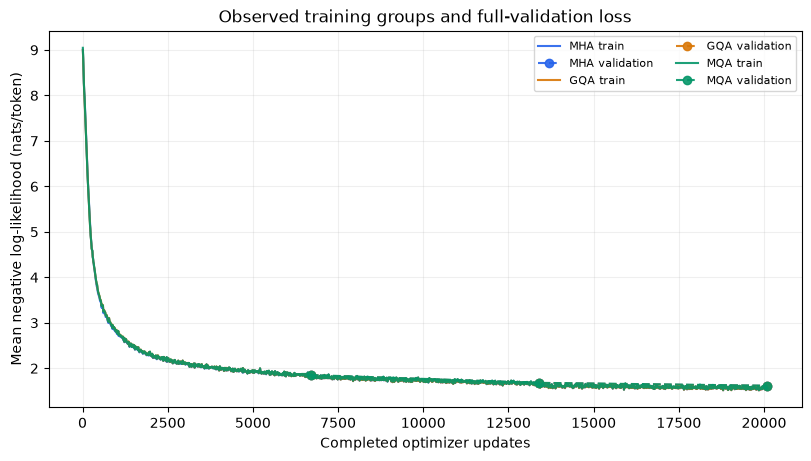

In [25]:
plot_training_curves(run)

### Plot the learning-rate schedule

All variants use the same update schedule.

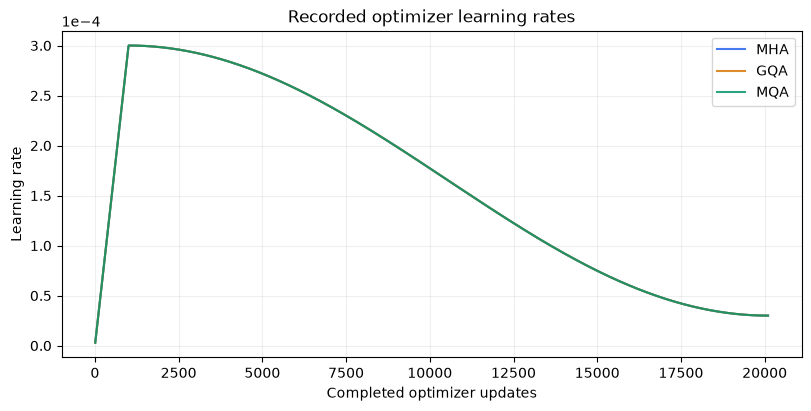

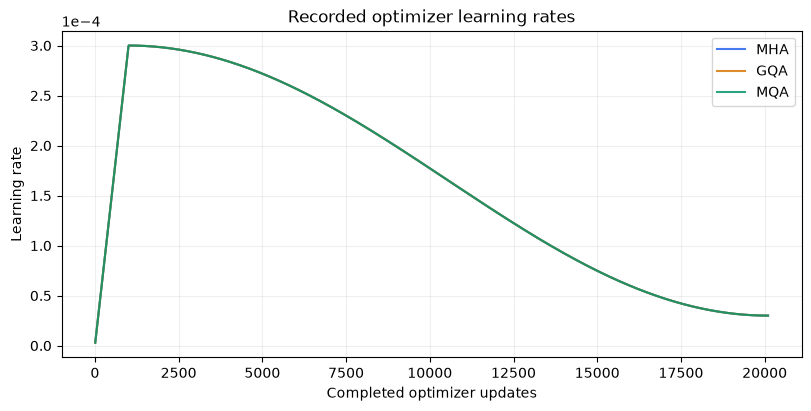

In [26]:
plot_learning_rate(run)

### Freeze the primary checkpoints

The primary comparison uses final checkpoints after equal token exposure. Best-validation checkpoints remain secondary artifacts.

In [27]:
primary_selection = freeze_primary_checkpoints(run)
primary_selection

{'identity': {'config': 'd2c73123277c40765407c0639eadee4c8119fbb183e677ed13fbb21f853e2df5',
  'environment': '848c8ee1ebedf04e29385547596bc1194b926e2e134b759979f38d35e73e32a9',
  'source': '136a46465a97fb525a50e318a9fc3cd055328b920e995805961ede7d6f4f6a2c'},
 'data_identity': {'source.json': '2ae5c03241f73645481b2974d52988e9bdf0fa161789783f46a3012d28c4b3ef',
  'source_receipt.json': '2ae5c03241f73645481b2974d52988e9bdf0fa161789783f46a3012d28c4b3ef',
  'splits.json': '0814d3d42a47de3f84bb33b4cd612dd2262d540254ad100054392b7a2ba94d9a',
  'tokenizer.json': '3858d983dff1582de27b1c78c1400548d7eb54e2aa29217bf306ab2258e82c6b',
  'tokens.json': 'ab0dfad493e264ce86b9f7eda69e00e2396095a00335287f82ec2e155fce895c'},
 'policy': 'final_after_equal_fixed_epochs',
 'variants': {'mha': {'path': 'models/mha/final.pt',
   'sha256': '73b17ae13844a61d62f6418a7d75ac7fb772882a7e76c7d25b4b8691fcdaddd6',
   'tokens_seen': 164637696},
  'gqa': {'path': 'models/gqa/final.pt',
   'sha256': '1266c5fe770d878ce6955fc8

### Evaluate the baseline on test

Use the same held-out targets and denominator as neural evaluation.

In [28]:
evaluate_unigram(run, tokens, unigram, split="test")

Unigram test:   0%|          | 0/18 [00:00<?, ?it/s]

{'total_nll': 14059738.73667622,
 'predicted_tokens': 2358938,
 'nll': 5.9601985031722835,
 'perplexity': 387.6870737141587,
 'perplexity_overflow': False,
 'variant': 'unigram',
 'split': 'test',
 'windows': 2304,
 'split_origin': 'derived from the official validation split',
 'baseline_sha256': 'a1761dcbc0c7e40eeb539cde5aaf40f6ef11e5039c8790571df0aeb5372ed7c5',
 'token_manifest_sha256': '993ead9059c284a7347258aa6cafc9fa195fe09c7b2761752e4fcb4cea888dc4',
 'path': '/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/unigram_test.json'}

### Evaluate MHA on test

Compute aggregate token-weighted NLL, then exponentiate once for perplexity. This cell cannot start training.

In [29]:
mha_evaluation = evaluate_variant(run, tokens, "mha")
mha_evaluation

Evaluate:   0%|          | 0/576 [00:00<?, ?it/s]

{'total_nll': 3809094.4243164062,
 'predicted_tokens': 2358938,
 'nll': 1.6147496985153516,
 'perplexity': 5.026629593144403,
 'perplexity_overflow': False,
 'windows': 2304,
 'padding_targets': 358,
 'elapsed_seconds': 58.397597417002544,
 'variant': 'mha',
 'split': 'test',
 'split_origin': 'derived from the official validation split',
 'checkpoint_kind': 'final',
 'checkpoint_sha256': '73b17ae13844a61d62f6418a7d75ac7fb772882a7e76c7d25b4b8691fcdaddd6',
 'token_manifest_sha256': '993ead9059c284a7347258aa6cafc9fa195fe09c7b2761752e4fcb4cea888dc4',
 'device': 'mps',
 'precision': 'float32',
 'parameter_count': 13767552,
 'path': '/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/mha_test.json'}

### Evaluate GQA on test

Compute aggregate token-weighted NLL, then exponentiate once for perplexity. This cell cannot start training.

In [30]:
gqa_evaluation = evaluate_variant(run, tokens, "gqa")
gqa_evaluation

Evaluate:   0%|          | 0/576 [00:00<?, ?it/s]

{'total_nll': 3808174.439453125,
 'predicted_tokens': 2358938,
 'nll': 1.6143596989209232,
 'perplexity': 5.02466959186643,
 'perplexity_overflow': False,
 'windows': 2304,
 'padding_targets': 358,
 'elapsed_seconds': 52.86305875000107,
 'variant': 'gqa',
 'split': 'test',
 'split_origin': 'derived from the official validation split',
 'checkpoint_kind': 'final',
 'checkpoint_sha256': '1266c5fe770d878ce6955fc878521b2d9b27e647017112e68c667bf2b8cc4493',
 'token_manifest_sha256': '993ead9059c284a7347258aa6cafc9fa195fe09c7b2761752e4fcb4cea888dc4',
 'device': 'mps',
 'precision': 'float32',
 'parameter_count': 12440448,
 'path': '/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/gqa_test.json'}

### Evaluate MQA on test

Compute aggregate token-weighted NLL, then exponentiate once for perplexity. This cell cannot start training.

In [31]:
mqa_evaluation = evaluate_variant(run, tokens, "mqa")
mqa_evaluation

Evaluate:   0%|          | 0/576 [00:00<?, ?it/s]

{'total_nll': 3824295.3569335938,
 'predicted_tokens': 2358938,
 'nll': 1.6211936714460464,
 'perplexity': 5.059125647573569,
 'perplexity_overflow': False,
 'windows': 2304,
 'padding_targets': 358,
 'elapsed_seconds': 51.68357799999649,
 'variant': 'mqa',
 'split': 'test',
 'split_origin': 'derived from the official validation split',
 'checkpoint_kind': 'final',
 'checkpoint_sha256': '9cdc2028264f67a7fef1414616ea47dbb016119cbfa4520a0e3c9996b174dce6',
 'token_manifest_sha256': '993ead9059c284a7347258aa6cafc9fa195fe09c7b2761752e4fcb4cea888dc4',
 'device': 'mps',
 'precision': 'float32',
 'parameter_count': 12219264,
 'path': '/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/evaluation/mqa_test.json'}

### Compare held-out quality

One-seed observations on synthetic stories. Parameter counts differ because KV heads differ; no other component is widened to hide that difference.

In [32]:
comparison_table(run)

,variant,status,split,nll,perplexity,predicted_tokens,parameter_count,checkpoint_sha256
0,mha,measured,test,1.614750,5.026630,2358938,13767552.0,73b17ae13844a61d62f6418a7d75ac7fb772882a7e76c7...
1,gqa,measured,test,1.614360,5.024670,2358938,12440448.0,1266c5fe770d878ce6955fc878521b2d9b27e647017112...
2,mqa,measured,test,1.621194,5.059126,2358938,12219264.0,9cdc2028264f67a7fef1414616ea47dbb016119cbfa452...
3,unigram,measured,test,5.960199,387.687074,2358938,NaN,NaN


### Prepare identical benchmark workloads

Fixed held-out tokens and fixed append counts eliminate generation/EOS workload differences. Prompt-plus-continuation lengths above 1,024 are systems-only measurements.

In [33]:
fixtures = prepare_benchmark_fixtures(run, tokens)
fixtures

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/benchmarks/fixtures.npz')

### Benchmark MHA

Actual trained-checkpoint parity is checked before timing. Five warm-ups and twenty trials compare cached versus full-prefix decoding, with synchronized timing and logging outside timed regions.

In [34]:
mha_benchmark = benchmark_variant(run, fixtures, "mha")
mha_benchmark["path"]

Benchmark MHA:   0%|          | 0/10 [00:00<?, ?it/s]

'/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/benchmarks/mha_summary.json'

### Benchmark GQA

Actual trained-checkpoint parity is checked before timing. Five warm-ups and twenty trials compare cached versus full-prefix decoding, with synchronized timing and logging outside timed regions.

In [35]:
gqa_benchmark = benchmark_variant(run, fixtures, "gqa")
gqa_benchmark["path"]

Benchmark GQA:   0%|          | 0/10 [00:00<?, ?it/s]

'/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/benchmarks/gqa_summary.json'

### Benchmark MQA

Actual trained-checkpoint parity is checked before timing. Five warm-ups and twenty trials compare cached versus full-prefix decoding, with synchronized timing and logging outside timed regions.

In [36]:
mqa_benchmark = benchmark_variant(run, fixtures, "mqa")
mqa_benchmark["path"]

Benchmark MQA:   0%|          | 0/10 [00:00<?, ?it/s]

'/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/benchmarks/mqa_summary.json'

### Plot compact cache growth

Logical bytes and allocated capacity are distinct. Cache ratios do not describe total application memory.

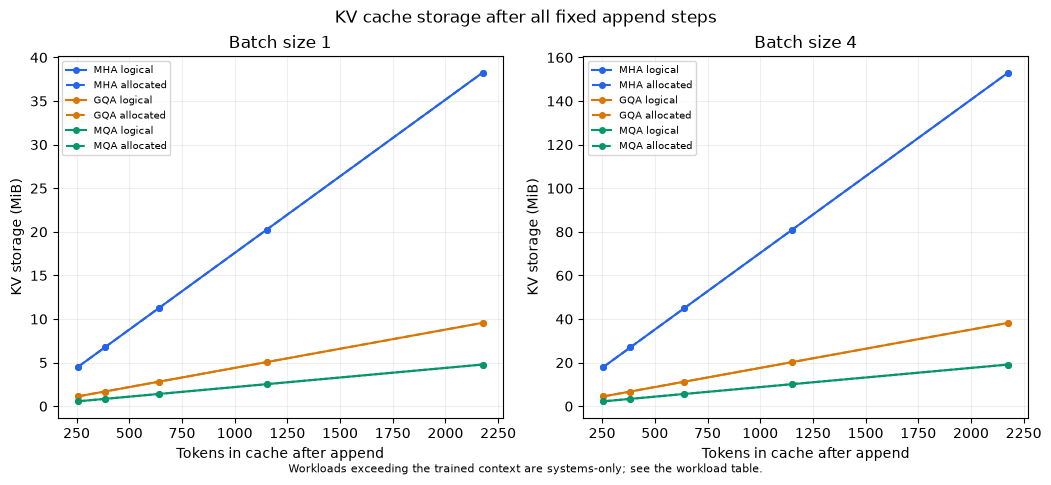

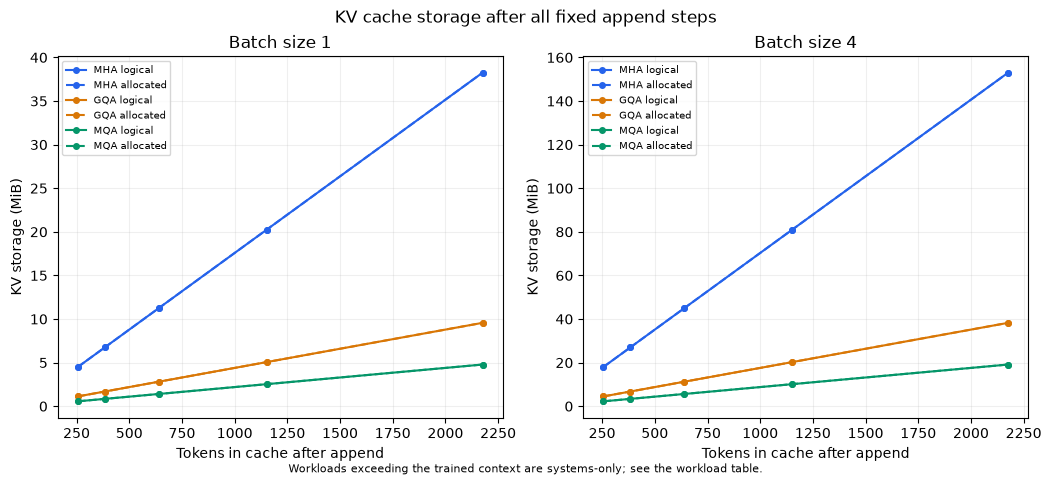

In [37]:
plot_cache_growth(run)

### Plot prefill latency

Median and p95 summarize repeated trials for this implementation, precision, and hardware.

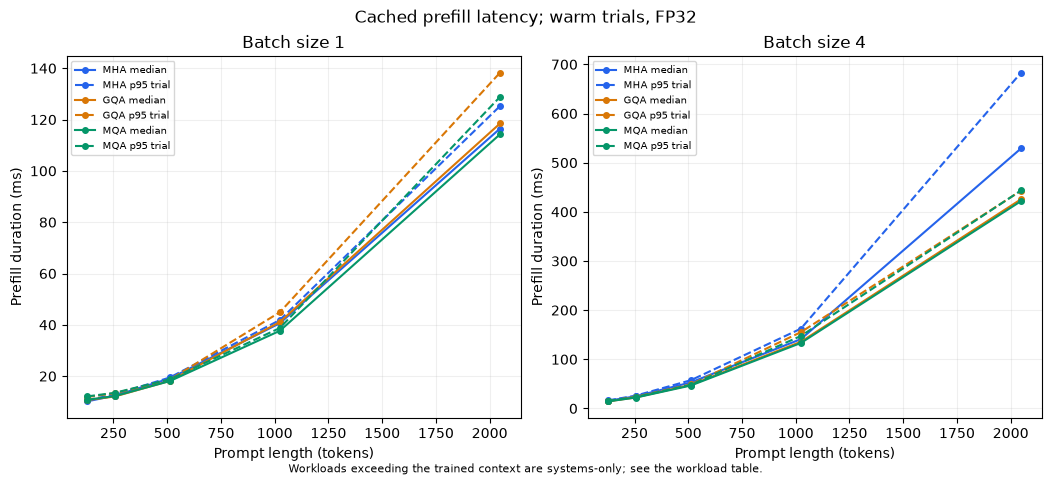

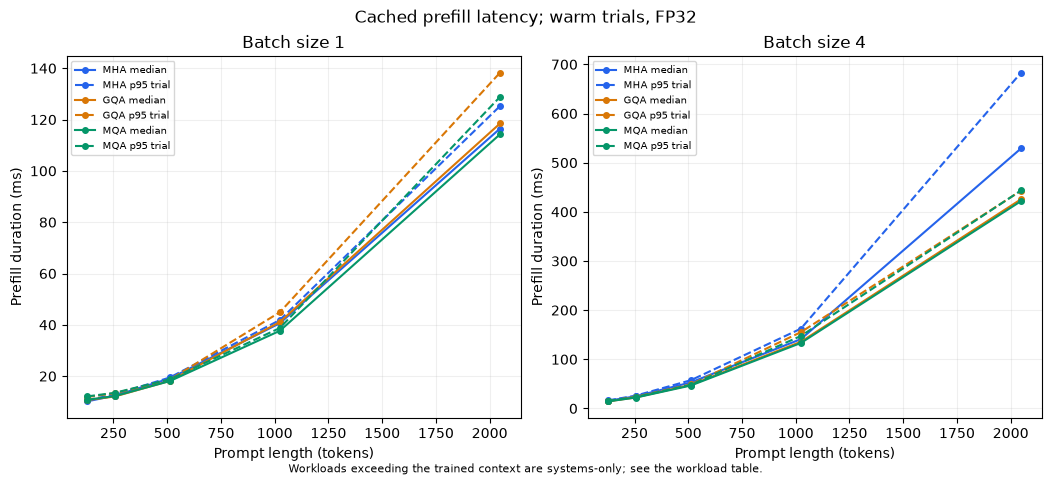

In [38]:
plot_prefill_latency(run)

### Plot decode latency

Each trial measures 128 append-token forwards. Its mean milliseconds per step is not an individual-token tail latency statistic.

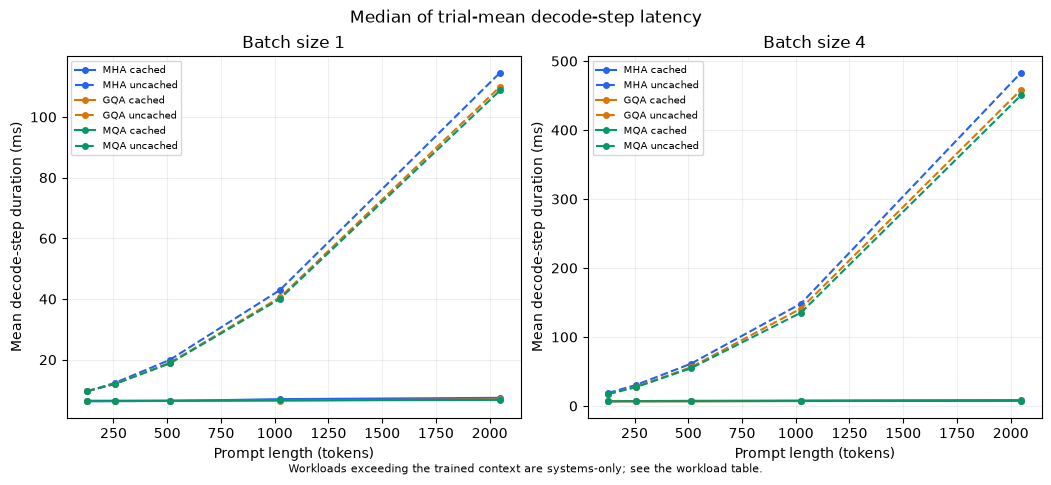

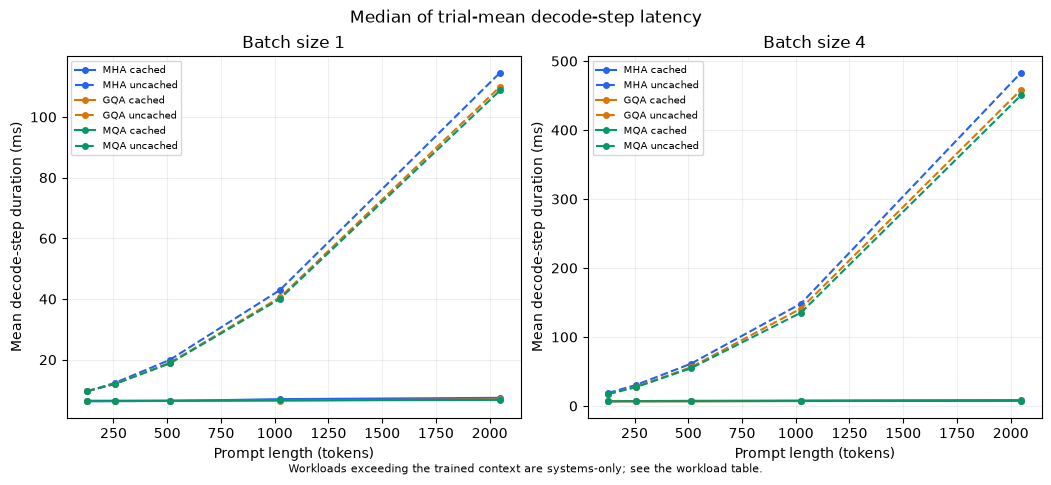

In [39]:
plot_decode_latency(run)

### Compare quality and inference cost

Keep held-out quality, cache memory, and actual timing visible together without declaring a universal winner.

In [40]:
quality_cost_table(run)

,variant,device,prompt_length,batch_size,decode_steps,systems_only,nll,perplexity,parameter_count,logical_kv_bytes,allocated_kv_bytes,cached_prefill_ms_median,cached_ms_per_step_median,cached_ms_per_step_p95,uncached_ms_per_step_median,cached_tokens_per_second_median
10,gqa,mps,128,1,128,False,1.614360,5.024670,12440448.0,1179648,1179648,10.687437,6.418741,6.493992,9.668518,155.793797
0,mha,mps,128,1,128,False,1.614750,5.026630,13767552.0,4718592,4718592,10.183167,6.290908,6.350529,9.549761,158.959571
20,mqa,mps,128,1,128,False,1.621194,5.059126,12219264.0,589824,589824,10.783104,6.472924,6.567908,9.682132,154.489705
12,gqa,mps,256,1,128,False,1.614360,5.024670,12440448.0,1769472,1769472,12.071667,6.444832,6.677418,11.999647,155.163200
2,mha,mps,256,1,128,False,1.614750,5.026630,13767552.0,7077888,7077888,12.393396,6.330780,6.420785,12.363838,157.958431
22,mqa,mps,256,1,128,False,1.621194,5.059126,12219264.0,884736,884736,12.218521,6.455091,6.532395,11.984428,154.916594
14,gqa,mps,512,1,128,False,1.614360,5.024670,12440448.0,2949120,2949120,18.169917,6.485188,6.664168,18.978025,154.197642
4,mha,mps,512,1,128,False,1.614750,5.026630,13767552.0,11796480,11796480,19.090312,6.411466,6.456043,19.944435,155.970652
24,mqa,mps,512,1,128,False,1.621194,5.059126,12219264.0,1474560,1474560,18.070917,6.499425,6.583405,18.786343,153.859773
16,gqa,mps,1024,1,128,True,1.614360,5.024670,12440448.0,5308416,5308416,41.095250,6.556562,7.556931,40.535473,152.519569


### Configure the walkthrough

Use a short example. Attention maps describe weights, not model reasoning or causal explanations.

In [41]:
WALKTHROUGH_VARIANT = "gqa"
WALKTHROUGH_TEXT = "Lily found a small blue box under the old tree."

### Load one walkthrough model

Only this model remains resident for the following diagnostic cells.

In [42]:
walkthrough_model = load_model(run, WALKTHROUGH_VARIANT)

### Display one causal attention head

Rows are query tokens, columns are key tokens. Future positions must receive zero weight.

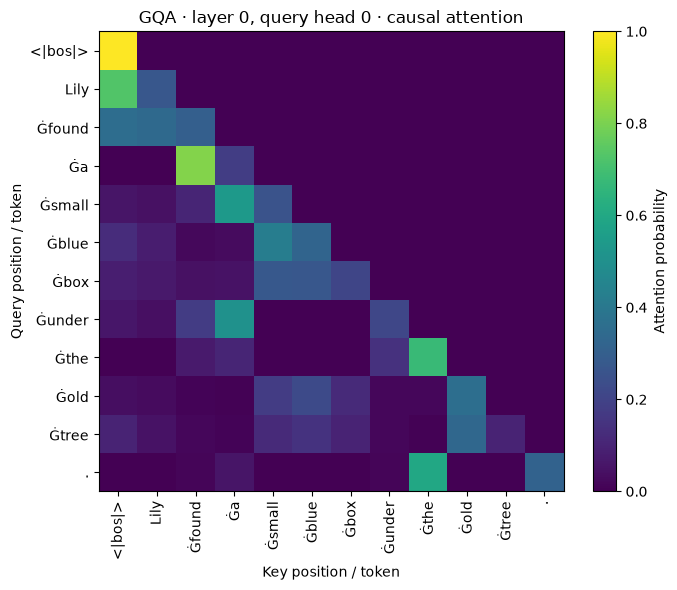

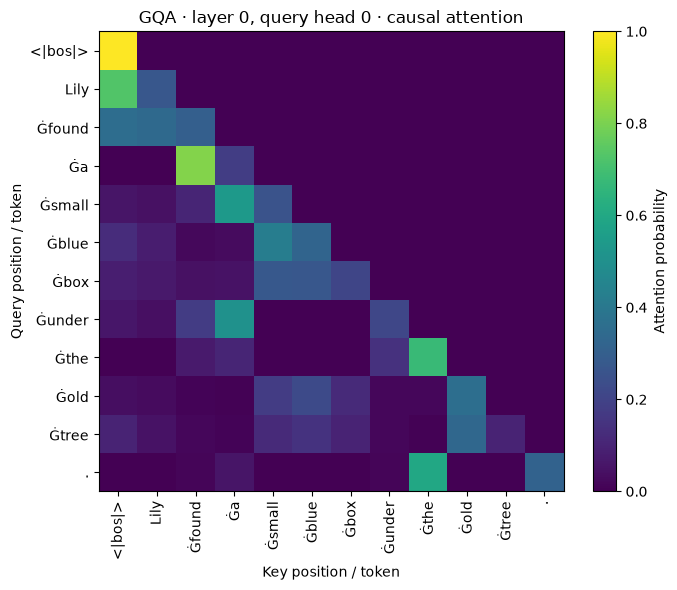

In [43]:
plot_attention(run, walkthrough_model, WALKTHROUGH_TEXT, layer=0, head=0)

### Inspect token-by-token cache growth

Allocated capacity stays fixed while the visible prefix and logical storage grow.

In [44]:
pd.DataFrame(inspect_cache_growth(run, walkthrough_model, WALKTHROUGH_TEXT))

,tokens,capacity,kv_heads,logical_bytes,allocated_bytes
0,1,12,2,4608,55296
1,2,12,2,9216,55296
2,3,12,2,13824,55296
3,4,12,2,18432,55296
4,5,12,2,23040,55296
5,6,12,2,27648,55296
6,7,12,2,32256,55296
7,8,12,2,36864,55296
8,9,12,2,41472,55296
9,10,12,2,46080,55296


### Compare cached and full outputs

Strict checkpoint-level checks include token, chunk, prefill, and last-logit paths.

In [45]:
compare_cached_outputs(run, walkthrough_model, WALKTHROUGH_TEXT)

{'passed': True,
 'device': 'mps:0',
 'batch_size': 1,
 'tokens': 12,
 'atol': 1e-05,
 'rtol': 0.0001,
 'full_vs_token': {'max_absolute_error': 1.71661376953125e-05},
 'full_vs_chunk': {'max_absolute_error': 1.71661376953125e-05},
 'full_vs_last_only': {'max_absolute_error': 5.7220458984375e-06},
 'chunk_lengths': [4, 4, 4],
 'prefill_tokens': 6,
 'kv_heads': 2,
 'cache_allocated_bytes': 55296,
 'variant': 'gqa'}

### Release the walkthrough model

Remove the notebook reference before additional inference work.

In [46]:
del walkthrough_model
release_memory(select_device())

### Choose demonstration prompts

The three fixed prompts support consistent inspection; edit USER_PROMPT for exploration. Sampling is illustrative, remains within the trained context, and is separate from benchmark workloads.

In [47]:
FIXED_PROMPTS = (
    "Once upon a time, a little fox found a key.",
    "Lily wanted to help her friend, but the bridge was broken.",
    "Tom opened the small box and saw",
)
USER_PROMPT = "A tiny bird was afraid to fly. One morning,"
PROMPTS = (*FIXED_PROMPTS, USER_PROMPT)
SAMPLING = dict(temperature=0.8, top_p=0.9, max_new_tokens=128, seed=2027)

### Generate with MHA

Generate and save one example for each prompt with the same sampling configuration. Models are released between calls.

In [48]:
mha_samples = [generate_variant(run, "mha", prompt, **SAMPLING) for prompt in PROMPTS]
pd.DataFrame([{"prompt": s["prompt"], "completion": s["completion"], "stop": s["stop_reason"]} for s in mha_samples])

Generate MHA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MHA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MHA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MHA:   0%|          | 0/128 [00:00<?, ?it/s]

,prompt,completion,stop
0,"Once upon a time, a little fox found a key.","It was small and long, but it kept her safe. ...",max_new_tokens
1,"Lily wanted to help her friend, but the bridge...","She felt sad and said, ""I don't know how to f...",max_new_tokens
2,Tom opened the small box and saw,a big pile of laundry. He wanted to try it. H...,max_new_tokens
3,"A tiny bird was afraid to fly. One morning,",the bird decided to spread its wings and fly ...,max_new_tokens


### Generate with GQA

Generate and save one example for each prompt with the same sampling configuration. Models are released between calls.

In [49]:
gqa_samples = [generate_variant(run, "gqa", prompt, **SAMPLING) for prompt in PROMPTS]
pd.DataFrame([{"prompt": s["prompt"], "completion": s["completion"], "stop": s["stop_reason"]} for s in gqa_samples])

Generate GQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate GQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate GQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate GQA:   0%|          | 0/128 [00:00<?, ?it/s]

,prompt,completion,stop
0,"Once upon a time, a little fox found a key.",The fox wanted to see what it could do. He de...,max_new_tokens
1,"Lily wanted to help her friend, but the bridge...",She was worried about it would fall. She aske...,max_new_tokens
2,Tom opened the small box and saw,a big red box. He opened the box and saw a lo...,max_new_tokens
3,"A tiny bird was afraid to fly. One morning,",it was sitting in a tree and the sky was blue...,max_new_tokens


### Generate with MQA

Generate and save one example for each prompt with the same sampling configuration. Models are released between calls.

In [50]:
mqa_samples = [generate_variant(run, "mqa", prompt, **SAMPLING) for prompt in PROMPTS]
pd.DataFrame([{"prompt": s["prompt"], "completion": s["completion"], "stop": s["stop_reason"]} for s in mqa_samples])

Generate MQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MQA:   0%|          | 0/128 [00:00<?, ?it/s]

Generate MQA:   0%|          | 0/128 [00:00<?, ?it/s]

,prompt,completion,stop
0,"Once upon a time, a little fox found a key.",The key was very fragile and needed to be tak...,max_new_tokens
1,"Lily wanted to help her friend, but the bridge...",She was sad because she had to wait for her m...,max_new_tokens
2,Tom opened the small box and saw,a big black thing. It had a lock on it and a ...,max_new_tokens
3,"A tiny bird was afraid to fly. One morning,",he decided to take a ride. He flapped his win...,max_new_tokens


### Assemble the technical report

Reads existing artifacts only; missing evidence is labeled incomplete. It does not train, evaluate, benchmark, or manufacture results.

In [51]:
report = assemble_report(run)
report

PosixPath('/Users/biitu/Documents/Growth/labs/attention-kv-cache/runs/run_001/report/report.md')

### Close this notebook session

Training writers are already closed by each fit. Close the run logger without marking unfinished work complete. An optional TensorBoard viewer can be stopped separately.

In [52]:
close_run(run)

## Interpretation boundaries

- One seed supports a scoped observation, not a robust architecture ranking.
- TinyStories is synthetic and uses simplified English; exact duplicate removal does not remove all near duplicates.
- Compact grouped matrix multiplication materializes scores; results are not FlashAttention or universal backend benchmarks.
- Memory snapshots are not exact MPS peaks; unified-memory categories cannot be summed blindly.
- Long-context performance tests do not establish long-context language quality.
- Best-validation checkpoints cannot silently replace the final equal-budget comparison.
- Optimization verification on 28 September: 120 project tests passed, four CUDA-only checks skipped. Bounded MPS checks passed at the same batch recipe; changing 2×4 to 4×2 changes FP32 rounding and does not reproduce the old training trajectory. Short synthetic timings and memory snapshots do not establish full-experiment speed or quality.